# 3 · Simulation and tuning

**Tumbller balance course — notebook 3 of 4.**

Now the model of notebook 1 and the controller of notebook 2 run together, with
the things a real robot adds: sensor noise, an accelerometer that feels
acceleration, coarse encoders without direction, PWM limits, a 5 ms clock. The
simulator runs a **Python port of the firmware's `balanceCar()`**, with the same
variable names and the same gains — so every number you tune here is a number
you can type into `BalanceCar.h`.

**You should come out knowing:**
- what each of the four gains does to the motion, and what "too little" and "too much" look like;
- where the stable region is, and how the balance and speed gains depend on each other;
- which real-world effects matter (saturation, friction, battery, noise) and how they show up;
- a tuning order that works, and how much to trust a simulation with estimated parameters.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML
import tumbller as tb
from tumbller import SERIES, INK, INK2, GRID, tidy
tb.use_style()
p = tb.Params()

g = tb.STOCK
ideal = tb.SensorModel(ideal=True)
PUSH = (1.0, 0.1, 3.0)          # at t = 1 s, for 0.1 s, 3 N at the centre of mass

def summary(res):
    # max tilt [deg], max travel [cm], time until back within 1 cm and 0.5 deg [s]
    out = (np.abs(res.x - res.x[0]) > 0.01) | (np.abs(res.theta_deg) > 0.5)
    t_settle = res.t[np.nonzero(out)[0][-1]] - PUSH[0] if out.any() else 0.0
    return np.max(np.abs(res.theta_deg)), np.max(np.abs(res.x)) * 100, t_settle

## 3.1 · What is in the simulator

`tb.simulate()` repeats, every 5 ms, what happens on the robot:

```
            ┌────────────────────── tb.simulate() ───────────────────────┐
 push ─────►│  PLANT  tb.dynamics()   nonlinear EoM + motor, RK4 at 1 ms │
            │     │ true x, θ, θ'                                        │
            │     ▼                                                      │
            │  SENSORS  accelerometer angle (feels acceleration, noise)  │
            │           gyro rate (bias, noise, 1/131 °/s steps)         │
            │           encoder edges (whole counts, no direction)       │
            │     │                                                      │
            │     ▼                                                      │
            │  FIRMWARE  tb.FirmwareController.tick()                    │
            │     Kalman filter → balance PD (5 ms) + speed PI (40 ms)   │
            │     → PWM, clipped to ±255, cut off beyond ±22°            │
            │     │ u, held for 5 ms                                     │
            └─────┴──────────────────────────────────────────────────────┘
```

| argument | meaning |
|---|---|
| `gains` | `tb.Gains(kp_balance, kd_balance, kp_speed, ki_speed)` in firmware units |
| `theta0_deg` | tilt at release |
| `push=(t, duration, force)` | horizontal shove at the centre of mass |
| `speed_cmd=lambda t: ...` | `setting_car_speed` over time (counts per 40 ms) |
| `sensors=tb.SensorModel(...)` | noise, bias, mounting offset; `ideal=True` switches all of it off |
| `p.with_(...)` | change any physical parameter, e.g. `p.with_(v_batt=7.0)` |

## 3.2 · Baseline: the stock gains

Stock gains, default sensors, a 3 N push for 0.1 s — about a firm poke with a finger.

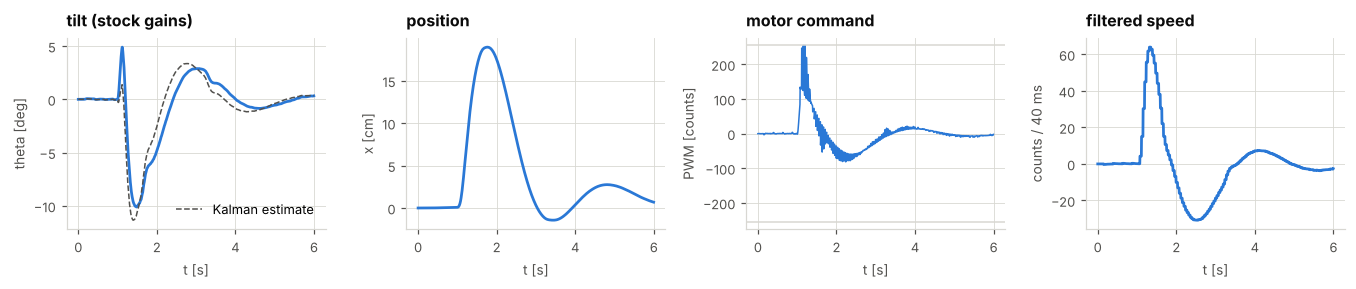

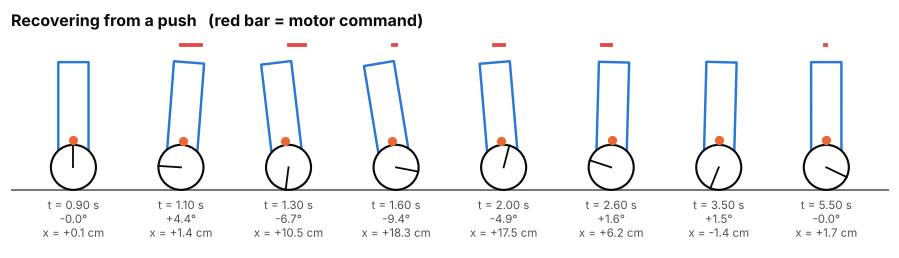

max tilt 10.1 deg, max travel 19.0 cm, settled after 4.8 s


In [2]:
base = tb.simulate(p, g, theta0_deg=0, t_end=6, push=PUSH)
tb.plot_run(base, "tilt (stock gains)", show_est=True)
plt.show()
tb.filmstrip(base, [0.9, 1.1, 1.3, 1.6, 2.0, 2.6, 3.5, 5.5], title="Recovering from a push")
plt.show()
print("max tilt %.1f deg, max travel %.1f cm, settled after %.1f s" % summary(base))

Read the sequence: the push tips the body forward; the wheels sprint forward
(PWM briefly at the limit) and overtake it, so the body now leans *back*; leaning
back it brakes, rolls back to where it started and straightens up. Fast tilt
recovery, slow return to the spot — the two time scales of notebook 2.

Run the next cell for the animation:

In [ ]:
HTML(tb.animate(base, every=6, title="Stock gains, 3 N push").to_jshtml())

## 3.3 · Try it yourself

Sliders for the four gains and the push. (Needs `ipywidgets`; the output of this
cell is not stored in the file — run it.)

In [ ]:
try:
    from ipywidgets import interact, FloatSlider, Checkbox

    def explore(kp_balance=55, kd_balance=0.75, kp_speed=10, ki_speed=0.26,
                push_N=3.0, real_sensors=True):
        gains = tb.Gains(kp_balance, kd_balance, kp_speed, ki_speed)
        res = tb.simulate(p, gains, theta0_deg=0, t_end=6, push=(1.0, 0.1, push_N),
                          sensors=None if real_sensors else ideal)
        axs = tb.plot_run(base, "tilt angle", label="stock")
        tb.plot_run(res, axs=axs, label="yours")
        axs[0].legend()
        plt.show()
        print("FELL OVER" if res.fell else "max tilt %.1f deg, max travel %.1f cm, settled after %.1f s" % summary(res),
              f"   | linear stability measure {tb.stability_margin(p, gains):.3f} (<1 = stable)")

    interact(explore,
             kp_balance=FloatSlider(min=0, max=300, step=5, value=55, continuous_update=False),
             kd_balance=FloatSlider(min=0, max=10, step=0.25, value=0.75, continuous_update=False),
             kp_speed=FloatSlider(min=0, max=30, step=1, value=10, continuous_update=False),
             ki_speed=FloatSlider(min=0, max=2, step=0.02, value=0.26, continuous_update=False),
             push_N=FloatSlider(min=0, max=8, step=0.5, value=3, continuous_update=False),
             real_sensors=Checkbox(value=True))
except ImportError:
    print("pip install ipywidgets   (then restart the kernel) to get the sliders")

## 3.4 · The balance loop: `kp_balance` and `kd_balance`

One gain at a time, everything else stock.

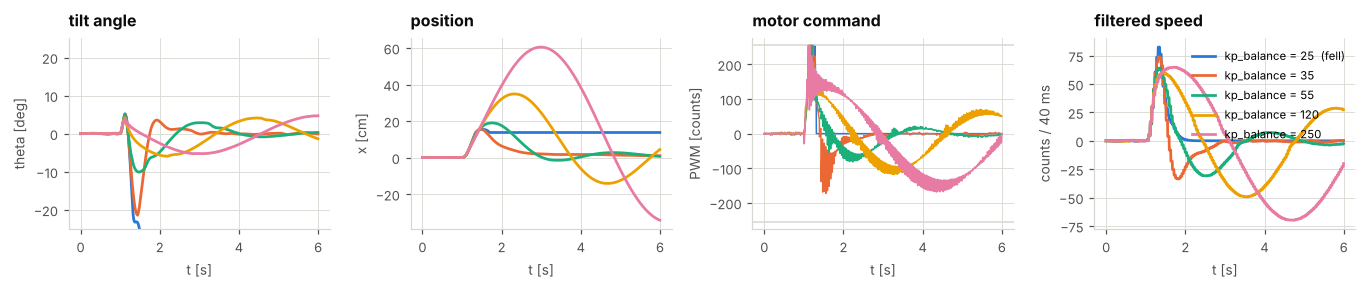

In [5]:
def sweep(name, values, t_end=6, ylim=None, **kw):
    axs = None
    for v in values:
        res = tb.simulate(p, g.with_(**{name: v}), theta0_deg=0, t_end=t_end, push=PUSH, **kw)
        tag = f"{name} = {v:g}" + ("  (fell)" if res.fell else "")
        axs = tb.plot_run(res, "tilt angle", label=tag) if axs is None else tb.plot_run(res, axs=axs, label=tag)
    axs[3].legend(fontsize=7.5, loc="upper right")
    if ylim:
        axs[0].set_ylim(*ylim)
    plt.show()

sweep("kp_balance", [25, 35, 55, 120, 250], ylim=(-25, 25))

- **Too low (25):** falls. Not because gravity wins — 25 is still far above the
  minimum of about 2 from notebook 2 — but because the *speed loop's positive
  feedback* (`kp_speed = 10`) needs a stiff balance loop to lean against.
  **The two loops are tuned as a pair.**
- **Low (35):** stands, but is thrown back to about −20° — a hair from the ±22° cut-off.
- **High (120, 250):** very little tilt, but the robot wanders off further and
  takes ever longer to come home, in slow wide swings. A stiff balance loop
  refuses the lean that the speed loop is asking for. On hardware, high `kp_balance` additionally excites
  everything the model does not contain: gear backlash, flexing chassis, tyre squish.

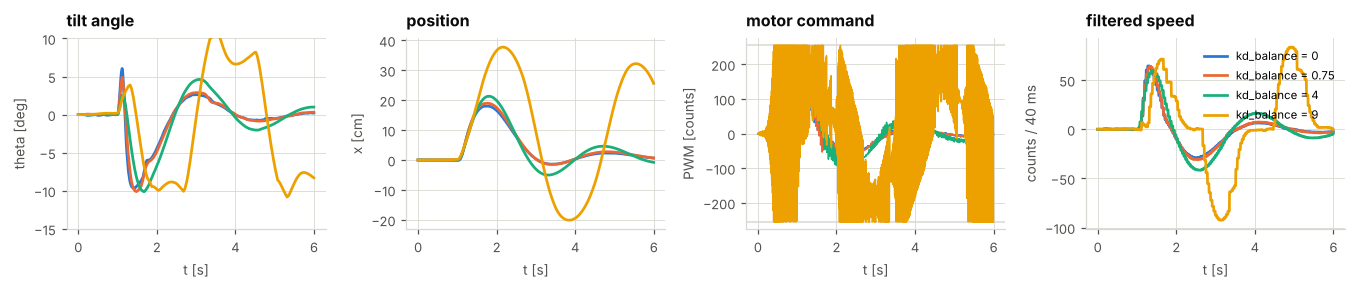

at rest, default sensor noise:   kd_balance   PWM jitter (std)   wheel jitter
                                     0.00          1.3           3.1 mm
                                     0.75          1.0           4.0 mm


                                     2.00          0.9           3.4 mm
                                     4.00          0.9           3.9 mm
                                     8.00          4.1          13.7 mm
                                    10.00        182.7         755.6 mm

balance mode:                    kd_balance   pole [1/s]        damping ratio
   real motor                        0.00    -12.5 +47.4j        0.26
   real motor                        0.75    -29.4 +39.5j        0.60
   no back-EMF                       0.00     -0.0 +48.9j        0.00
   no back-EMF                       0.75    -16.9 +45.9j        0.35


In [6]:
sweep("kd_balance", [0, 0.75, 4, 9], ylim=(-15, 10))

print("at rest, default sensor noise:   kd_balance   PWM jitter (std)   wheel jitter")
for kd in [0, 0.75, 2, 4, 8, 10]:
    res = tb.simulate(p, g.with_(kd_balance=kd), theta0_deg=0, t_end=6)
    m = res.t > 3
    print(f"                                 {kd:8.2f}   {np.std(res.u[m]):10.1f}      {np.ptp(res.x[m])*1e3:8.1f} mm")

# damping of the fast balance mode (balance loop alone, continuous model)
print("\nbalance mode:                    kd_balance   pole [1/s]        damping ratio")
A, B = tb.linearize(p)
A0, B0 = tb.linearize(p.with_(w0_rated=1e4))          # hypothetical motor with almost no back-EMF
for label, (Ax, Bx) in [("real motor", (A, B)), ("no back-EMF", (A0, B0))]:
    for kd in [0, 0.75]:
        Kb = np.array([[0, 0, g.kp_balance, kd]]) * 180 / np.pi
        z = max(np.linalg.eigvals(Ax + Bx @ Kb), key=lambda e: e.imag)
        print(f"   {label:12s}                  {kd:8.2f}   {z.real:6.1f} {z.imag:+5.1f}j        {-z.real/abs(z):.2f}")

In this model `kd_balance` is a **weak knob** over a wide range: the push
response with 0 and with 0.75 is nearly the same, and at 9 the motor command is
thrashing between its limits.

The last table explains the weak effect. Two dampers act on the fast balance
mode: the gyro term and the motor's back-EMF. With the real motor the mode is
already damped without any D (damping ratio around 0.25); the stock
`kd_balance` raises that to about 0.6. Either way the fast motion is gone
within a tenth of a second — long before the slow speed-loop motion that
dominates what you see after a push. With a motor that had no back-EMF, the
same loop without D would ring almost undamped: there the D-term would be
essential. What a large `kd_balance` adds is **noise** — the raw gyro signal goes
straight into the PWM — and beyond a certain value the discrete loop goes
unstable outright.

Whether your real robot agrees is a good first experiment for notebook 4 — if it
needs clearly more D than the model, the model is missing something (backlash is
the usual suspect).

The whole picture at once: the stability measure (largest $|z|$ of the exact
discrete loop, notebook 2) over the plane of both balance gains.

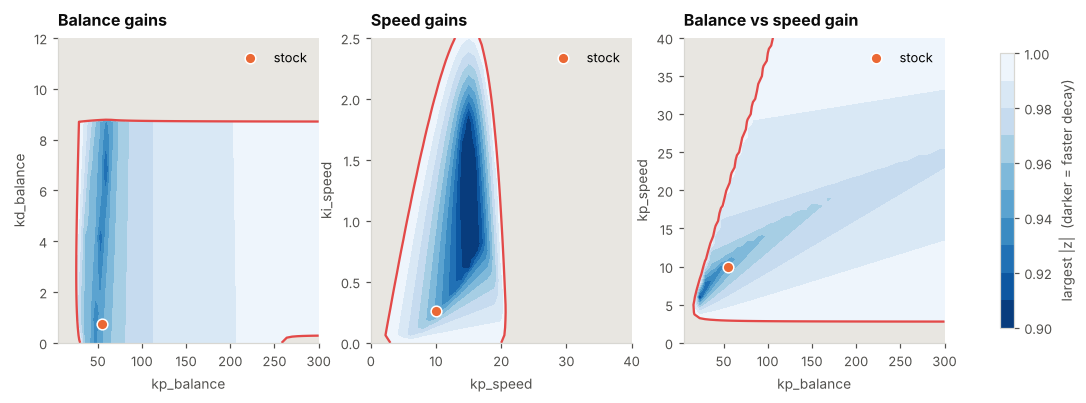

In [7]:
def stability_map(ax, xname, xs, yname, ys, title):
    Z = np.array([[tb.stability_margin(p, g.with_(**{xname: x, yname: y})) for x in xs] for y in ys])
    cf = ax.contourf(xs, ys, np.clip(Z, 0.9, 1.0), levels=np.linspace(0.9, 1.0, 11), cmap="Blues_r")
    ax.contourf(xs, ys, Z, levels=[1.0, 1e9], colors=["#e8e6e1"])
    ax.contour(xs, ys, Z, levels=[1.0], colors=[SERIES[7]], linewidths=1.5)
    ax.plot(getattr(g, xname), getattr(g, yname), "o", color=SERIES[1], ms=7, mec="white", label="stock")
    ax.grid(False); ax.legend(loc="upper right")
    tidy(ax, title, xname, yname)
    return cf

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
stability_map(axs[0], "kp_balance", np.linspace(5, 300, 50), "kd_balance", np.linspace(0, 12, 41),
              "Balance gains")
stability_map(axs[1], "kp_speed", np.linspace(0, 40, 41), "ki_speed", np.linspace(0, 2.5, 41),
              "Speed gains")
cf = stability_map(axs[2], "kp_balance", np.linspace(5, 300, 50), "kp_speed", np.linspace(0, 40, 41),
                   "Balance vs speed gain")
fig.colorbar(cf, ax=axs, label="largest |z|  (darker = faster decay)", shrink=0.9)
plt.show()

Grey is unstable, the red line is the boundary, darker blue means disturbances
die out faster. Three things to take from the maps:

1. **Left map:** the stable region in `kp_balance` is wide, with a floor on the
   left (set by the speed gains) and the fastest decay in a narrow band right
   around the stock value. `kd_balance` hardly matters until it hits a hard
   ceiling. Only in the bottom-right corner — very high `kp_balance`, almost no
   D — does the missing damping make the loop unstable: that is where the D-term earns its place.
2. **Middle map:** the speed loop has a clear **sweet spot**. Both too little
   and too much `kp_speed` are unstable. The stock values sit on the cautious
   edge of the dark area.
3. **Right map:** the boundary is a wedge. More `kp_speed` demands more
   `kp_balance`. If you change one, expect to revisit the other.

The maps assume perfect sensors, small motions and no saturation. They show
where *not* to go; inside the stable region, time-domain runs decide — as the
next section shows straight away.

## 3.5 · The speed loop: `kp_speed` and `ki_speed`

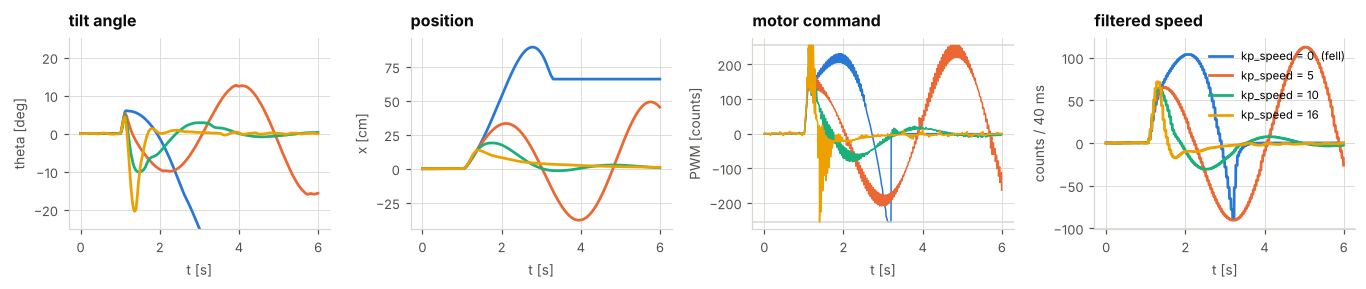

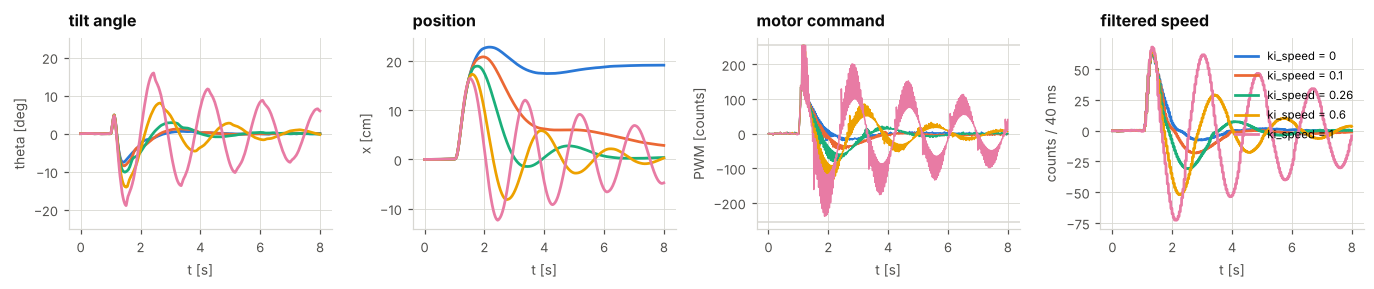

In [8]:
sweep("kp_speed", [0, 5, 10, 16], ylim=(-25, 25))
sweep("ki_speed", [0, 0.1, 0.26, 0.6, 1.0], t_end=8, ylim=(-25, 25))
# try:  sweep("ki_speed", [0.26, 1.0], t_end=8, ylim=(-25, 25), sensors=ideal)

- `kp_speed = 0`: nothing stops the roll — the robot keeps going until it falls.
  Too small (5): it brakes too gently and too late, and swings back and forth in
  growing arcs. Large (16): it brakes hard — the body is thrown back to about
  −20°, on the verge of the cut-off; a little more and it tips.
- `ki_speed = 0`: stands, but does not return (and would creep with a wrong zero
  angle, notebook 2). More integral brings it home faster, at the price of a
  bigger back-swing; at 1.0 it rocks back and forth without settling — the
  classic sign of an over-eager integrator.

That last result contradicts the middle map, which shows `ki_speed = 1` deep in
the dark, well-damped area. The difference is the **tilt estimate**. The map
assumes the controller knows the true angle. The real estimate is pulled by the
accelerometer whenever the robot accelerates (notebook 2), and that creates an
extra feedback path — acceleration → angle error → motor command — which the map
does not contain. Rerun the sweep with `sensors=ideal` and the rocking
disappears. The estimator is part of the loop, and it costs stability margin
exactly where the robot moves most.

## 3.6 · Reality checks

### How hard can you push it? — saturation

The motors give at most ±255. Small disturbances never get near that; large
ones hit the limit, and then the loop is effectively open.

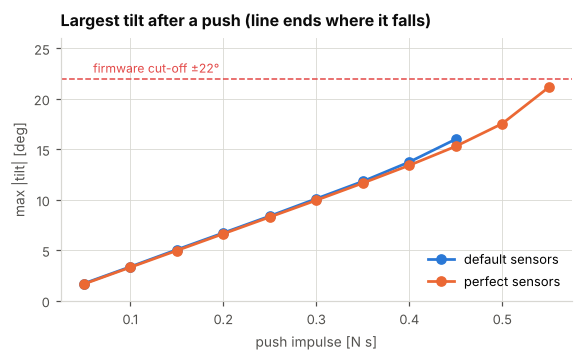

In [9]:
forces = np.arange(0.5, 7.1, 0.5)
fig, ax = plt.subplots(figsize=(6, 3.1))
for label, sm in [("default sensors", None), ("perfect sensors", ideal)]:
    tilt = []
    for F in forces:
        res = tb.simulate(p, g, theta0_deg=0, t_end=5, push=(1.0, 0.1, F), sensors=sm)
        tilt.append(np.nan if res.fell else np.max(np.abs(res.theta_deg)))
    ax.plot(forces * 0.1, tilt, "o-", label=label)
ax.axhline(22, color=SERIES[7], lw=1, ls="--")
ax.text(0.06, 22.6, "firmware cut-off ±22°", color=SERIES[7], fontsize=8)
ax.legend(loc="lower right"); ax.set_ylim(0, 26)
tidy(ax, "Largest tilt after a push (line ends where it falls)", "push impulse [N s]", "max |tilt| [deg]")
plt.show()

The tilt grows roughly in proportion to the push until the robot can no longer
recover. The limit is not the gains: it is top speed and the ±22° cut-off. With
real sensors the limit comes earlier, because the accelerometer corrupts the
angle estimate exactly during the push (notebook 2).

### Friction in the gearbox — the standing wobble

Real gearmotors need a minimum PWM before they move at all. Modelled as dry
friction between wheel and body:

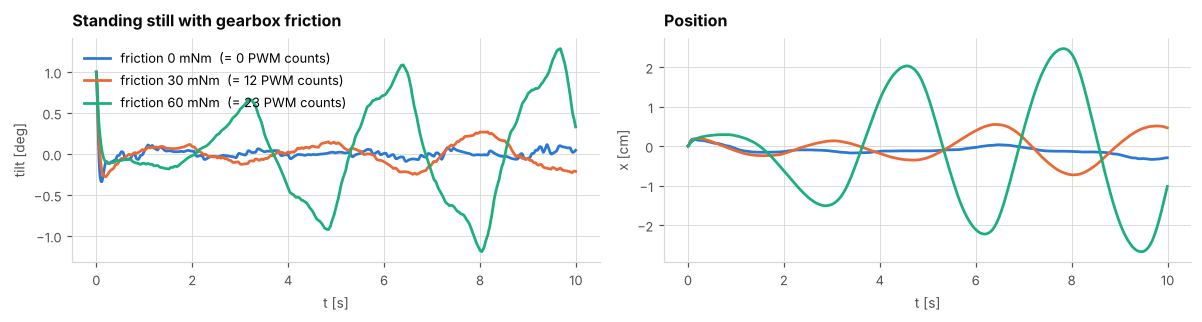

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3))
for tc in [0.0, 0.03, 0.06]:
    res = tb.simulate(p.with_(tau_coulomb=tc), g, theta0_deg=1, t_end=10)
    lab = f"friction {tc*1e3:.0f} mNm  (= {tc/p.k_m:.0f} PWM counts)"
    axs[0].plot(res.t, res.theta_deg, label=lab)
    axs[1].plot(res.t, res.x * 100, label=lab)
axs[0].legend()
tidy(axs[0], "Standing still with gearbox friction", "t [s]", "tilt [deg]")
tidy(axs[1], "Position", "t [s]", "x [cm]")
plt.tight_layout(); plt.show()

With friction the robot never quite stands still: it leans until the command is
big enough to break the motors loose, overshoots, and repeats — a slow, steady
rocking back and forth called a **limit cycle**. No gain setting removes it
completely; it is a property of the hardware. If your robot rocks gently on the
spot, this is the first suspect, not your tuning.

### Battery voltage

Voltage multiplies every gain (notebook 1). Same push, different charge:

In [11]:
print("battery   max tilt   max travel   (push 0.4 N s)")
for v in [8.4, 7.8, 7.4, 7.0, 6.5, 6.0]:
    res = tb.simulate(p.with_(v_batt=v), g, theta0_deg=0, t_end=6, push=(1.0, 0.1, 4.0))
    print(f" {v:.1f} V    " + ("fell over" if res.fell else
          f"{np.max(np.abs(res.theta_deg)):5.1f} deg   {np.max(np.abs(res.x))*100:6.1f} cm"))

battery   max tilt   max travel   (push 0.4 N s)
 8.4 V     13.6 deg     24.9 cm
 7.8 V     13.8 deg     25.5 cm
 7.4 V     14.0 deg     26.1 cm


 7.0 V     14.6 deg     27.2 cm
 6.5 V     17.5 deg     32.6 cm
 6.0 V    fell over


Performance degrades gently and then, close to the limit, suddenly. The firmware
refuses to run below 7.0 V for a reason. For tuning, the practical rule: **tune
on a charged battery and re-check on a tired one.**

### How wrong may the model be?

The masses, inertias and motor constants are estimates. Does the conclusion
"stock gains are stable" survive if they are off? 400 random robots, every
uncertain parameter varied independently (±25 % on masses and motor constants,
×0.6…1.6 on CoM height and body inertia, ×0.4…2.5 on rotor inertia, battery 7.0…8.4 V),
for three candidate values of the encoder resolution:

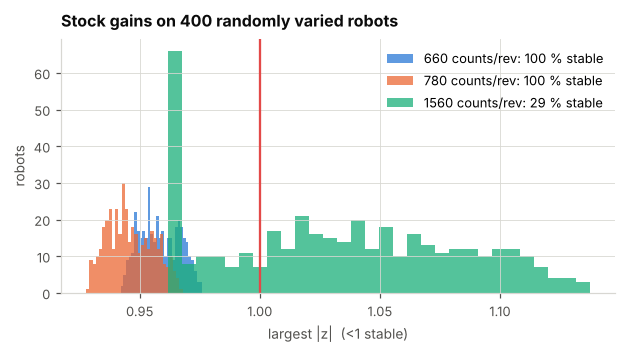

In [12]:
def random_robot(rng, cpr):
    f = lambda lo=0.75, hi=1.25: rng.uniform(lo, hi)
    return p.with_(m_body=p.m_body * f(), l=p.l * f(0.6, 1.6), I_body=p.I_body * f(0.6, 1.6),
                   I_rotor=p.I_rotor * f(0.4, 2.5), stall_rated=p.stall_rated * f(),
                   w0_rated=p.w0_rated * f(), v_batt=rng.uniform(7.0, 8.4), counts_per_rev=cpr)

fig, ax = plt.subplots(figsize=(6.5, 3))
for cpr in [660, 780, 1560]:
    rng = np.random.default_rng(0)
    m = np.array([tb.stability_margin(random_robot(rng, cpr), g) for _ in range(400)])
    ax.hist(m, bins=30, alpha=0.75, label=f"{cpr} counts/rev: {np.mean(m < 1)*100:.0f} % stable")
ax.axvline(1.0, color=SERIES[7], lw=1.5)
ax.legend()
tidy(ax, "Stock gains on 400 randomly varied robots", "largest |z|  (<1 stable)", "robots")
plt.show()

Two results:

- For the mechanical and motor parameters the stock gains are **robust**: all
  varied robots are stable. The qualitative lessons of this notebook do not hang
  on my estimates.
- The **encoder resolution** is different. It scales the speed loop directly
  (`kp_speed` is "PWM per count"), and doubling it pushes most robots out of the
  stable region. Since the real robot does balance with the stock gains, the
  model suggests the firmware sees something like 660–780 edges per wheel
  revolution rather than 1560 — but that is an inference, not a measurement.
  Counting them is the first experiment in notebook 4.

## 3.7 · Driving

The remote control does nothing more than set `setting_car_speed` (40 or 80 in
the stock firmware) and let the integral do the rest:

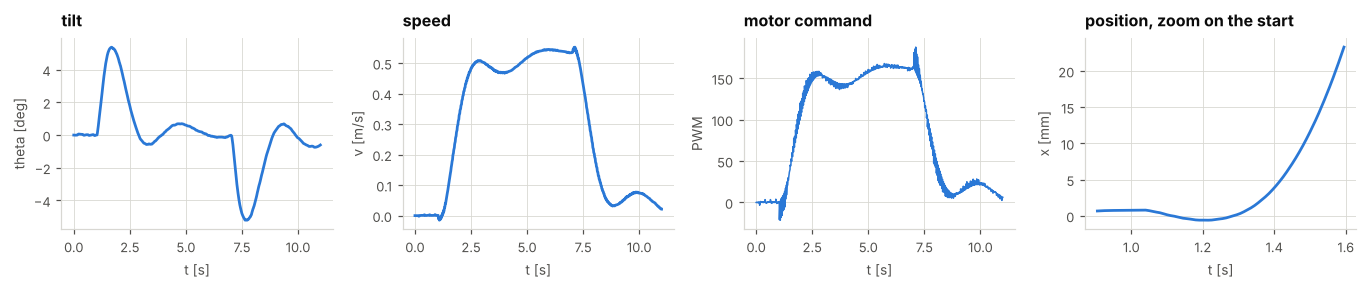

setting_car_speed = 80  ->  0.54 m/s  (80 counts per 40 ms = 0.54 m/s)

command   reached speed   mean PWM while cruising
    40      0.27 m/s            81
    80      0.54 m/s           162
   110      0.66 m/s           200


   140      0.66 m/s           201


In [13]:
drive = tb.simulate(p, g, theta0_deg=0, t_end=11, speed_cmd=lambda t: 80 if 1 <= t < 7 else 0)
fig, axs = plt.subplots(1, 4, figsize=(12.5, 2.7))
axs[0].plot(drive.t, drive.theta_deg); tidy(axs[0], "tilt", "t [s]", "theta [deg]")
axs[1].plot(drive.t, drive.v);         tidy(axs[1], "speed", "t [s]", "v [m/s]")
axs[2].plot(drive.t, drive.u, lw=1);   tidy(axs[2], "motor command", "t [s]", "PWM")
m = (drive.t > 0.9) & (drive.t < 1.6)
axs[3].plot(drive.t[m], drive.x[m] * 1000); tidy(axs[3], "position, zoom on the start", "t [s]", "x [mm]")
plt.tight_layout(); plt.show()

v_ss = drive.v[(drive.t > 6) & (drive.t < 7)].mean()
print(f"setting_car_speed = 80  ->  {v_ss:.2f} m/s  "
      f"(80 counts per 40 ms = {80/0.04/p.counts_per_rev*2*np.pi*p.r:.2f} m/s)")
print("\ncommand   reached speed   mean PWM while cruising")
for c in [40, 80, 110, 140]:
    r_ = tb.simulate(p, g, theta0_deg=0, t_end=8, speed_cmd=lambda t, c=c: c if t >= 1 else 0)
    mm = r_.t > 6.5
    print(f"  {c:4d}      " + ("fell over" if r_.fell else f"{r_.v[mm].mean():.2f} m/s          {r_.u[mm].mean():4.0f}"))

- To set off forward the robot first **leans** forward — and to get that lean the
  wheels start by rolling *backward* for an instant (last panel: a dip of well
  under a millimetre before it drives off). The same non-minimum-phase behaviour as in braking.
- Speed in m/s follows from the command by pure unit conversion — if the encoder
  resolution is right. Another reason to measure it.
- Cruising costs PWM: back-EMF has to be overcome. The faster it goes, the less
  of the ±255 range is left for balancing. Beyond a certain command the robot
  simply does not go any faster.

## 3.8 · A tuning order that works

Distilled from the experiments above. It is the order used in notebook 4 on the hardware.

| step | set | look for | too little | too much |
|---|---|---|---|---|
| 0 | zero angle, sensors, battery | angle reads ≈ 0 at the balance point | — | — |
| 1 | `kp_balance`, speed gains 0, hold the robot loosely | pushes back firmly against your hand | soft, falls through | buzzing, hard twitching |
| 2 | `kd_balance` | twitching calms down | fast ringing after a tap | grinding noise, hot motors |
| 3 | `kp_speed` (`ki_speed` = 0) | stops rolling after a nudge | rolls away | tips over shortly after a nudge |
| 4 | `ki_speed` | returns to its spot | stays where it stopped, creeps | slow growing rocking |
| 5 | re-check 1–4 | push test, low battery, driving | | |

Rules of thumb from the maps: change **one gain at a time**, in steps of about
20 %; when you raise `kp_speed`, be ready to raise `kp_balance`; stay away from
both edges of the stable region rather than near one of them.

A compact way to compare candidates is the push test of this notebook:

In [14]:
candidates = {
    "stock":            g,
    "softer balance":   g.with_(kp_balance=40),
    "stiffer balance":  g.with_(kp_balance=80),
    "more integral":    g.with_(ki_speed=0.4),
    "gentler speed":    g.with_(kp_speed=8, ki_speed=0.2),
}
print(f"{'':18s} kp_b   kd_b  kp_s  ki_s | max tilt  travel  settled | same test at 7.0 V with gearbox friction")
for name, c in candidates.items():
    a = tb.simulate(p, c, theta0_deg=0, t_end=8, push=PUSH)
    b = tb.simulate(p.with_(v_batt=7.0, tau_coulomb=0.03), c, theta0_deg=0, t_end=8, push=PUSH)
    fa = "      fell over        " if a.fell else "%5.1f deg %5.1f cm %5.1f s" % summary(a)
    fb = "fell over" if b.fell else "%5.1f deg %5.1f cm" % summary(b)[:2]
    print(f"{name:18s} {c.kp_balance:4.0f} {c.kd_balance:6.2f} {c.kp_speed:5.1f} {c.ki_speed:5.2f} | {fa} | {fb}")

                   kp_b   kd_b  kp_s  ki_s | max tilt  travel  settled | same test at 7.0 V with gearbox friction


stock                55   0.75  10.0  0.26 |  10.1 deg  19.0 cm   4.8 s |  10.1 deg  20.4 cm
softer balance       40   0.75  10.0  0.26 |  17.0 deg  15.9 cm   4.2 s |  17.5 deg  17.6 cm


stiffer balance      80   0.75  10.0  0.26 |   6.9 deg  25.3 cm   7.0 s |   7.0 deg  26.9 cm
more integral        55   0.75  10.0  0.40 |  11.7 deg  18.0 cm   5.0 s |  11.9 deg  19.4 cm


gentler speed        55   0.75   8.0  0.20 |   7.8 deg  24.1 cm   6.7 s |   7.9 deg  26.1 cm


Add your own rows. A setting is only good if it is also good in the right-hand
column — on the tired battery, with friction.

## 3.9 · Take-aways

- `kp_balance`: stiffness of the upright. Has a floor (set by the speed loop);
  too high makes the robot wander, and on hardware excites what the model omits.
- `kd_balance`: damps the fast balance mode, which the motors' back-EMF damps
  already — little visible effect; too much is noise.
- `kp_speed`: the gain with a sweet spot. Too little rolls away, too much tips over.
- `ki_speed`: brings it home; too much rocks.
- The tilt estimator is part of the loop: stability maps drawn for perfect
  sensors are optimistic, most of all for `ki_speed`.
- Saturation, friction and battery voltage set the limits of what any tuning can do.
- The conclusions are robust against my parameter estimates — except for the
  encoder resolution, which must be measured.

## Exercises

1. Find, with the sliders or `tb.simulate`, the smallest `kp_balance` that
   survives the standard push with `kp_speed = 6`. Compare with the right-hand stability map.
2. Make the robot taller: `p.with_(l=0.10, I_body=4e-3)`. Do the stock gains
   still work? Which gain would you change first?
3. Simulate a 2° mounting offset (`tb.SensorModel(mount_offset_deg=2)`) with
   `ki_speed = 0` and with 0.26. Where does each end up after 10 s?
4. Replace the 0.1 s push by a long gentle one, `push=(1, 2.0, 0.5)`. Which way
   does the robot lean while being pushed, and why?
5. Set `sensors=tb.SensorModel(encoder_true_sign=True)` and repeat the 0.4 N s
   push. Does knowing the true direction of rotation help? When could the
   firmware's guess (sign of the PWM) be wrong?